In [1]:
### standard libraries
import time
import numpy as np
import matplotlib.pyplot as plt

### my modules
from fast_volume_align_ot import utils, plots, transforms, distances

In [2]:
def points_to_voxel_index(p, L):
    """
    converts points (x,y,z) in [-1,1]^3 to voxel indices in [0, L-1]^3
    input: p is 3 X n_points array
    """

    p_norm = (p + 1) / 2 * (L-1)
    v_idx = np.floor(p_norm.T).astype('int')

    return v_idx


def fill_voxel_array(v_idx, L, value=1):
    """fill voxel array at specified index with value"""

    ### figure out best conventions, currently:
    ### * UPDATE THIS
    ### - Cartesian x --> Numpy z (axis=0)
    ### - Cartesian y --> Numpy y (axis=1)
    ### - Cartesian z --> Numpy x (axis=2)

    f = np.zeros((L,L,L))

    vx = v_idx[:, 0]
    vy = v_idx[:, 1]
    vz = v_idx[:, 2]

    f[vx, -vz, vy] = value
    
    return f


def generate_voxel_array_from_points(p, L, value=1):
    
    v_idx = points_to_voxel_index(p, L)
    f = fill_voxel_array(v_idx, L, value)

    return f

In [3]:
p = np.array([[0, -0.33, 0.33], [0, 0, -0.33], [0, 0.33, 0.33]]).T

# p = np.array([[0, -0.33, 0.33], [0, 0, -0.33], [0, 0.33, 0.33], [-0.5, 0.5, -0.5]]).T

# p = np.array([0, 0, 0.5]).reshape(3,1)

### what conventions / axes / order to use here?
omega = np.deg2rad(0)
theta = np.deg2rad(180)
phi = np.deg2rad(0)

R1 = transforms.rotate_z(omega)
R2 = transforms.rotate_y(theta)
R3 = transforms.rotate_z(phi)
R = R3 @ R2 @ R1

### rotate z by omega -> rotate y by theta -> rotate z by phi 
q = R @ p

In [4]:
# p, np.round(q, 2)

In [5]:
# p = np.array([[0, 0, 0.1,], [0, 0, 0.6]]).T
# q = np.array([[0.2, 0, 0.1,], [0.2, 0, 0.6]]).T

# theta = np.deg2rad(180)
# q = transforms.rotate_y(theta) @ q

	 original


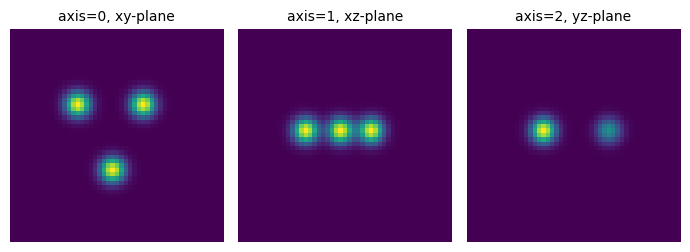

	 rotated


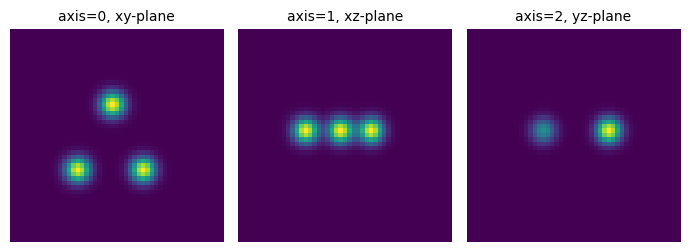

In [6]:
L = 49

f = generate_voxel_array_from_points(p, L)
g = generate_voxel_array_from_points(q, L)

sigma = 2
z = utils.generate_centered_gaussian(L=L, d=3, sigma=sigma)

F = utils.signal_convolution(f, z)
G = utils.signal_convolution(g, z)

print('\t original')
plots.orthogonal_2D_projection_plot(F)
print('\t rotated')
plots.orthogonal_2D_projection_plot(G)

In [7]:
U = transforms.Transform(F, d=3, apply_ramp=False).icdf_transform()[0]
V = transforms.Transform(G, d=3, apply_ramp=False).icdf_transform()[0]

In [8]:
# ### Test rotations in either theta or phi individually by shifting tensor

# n_phi, n_points, n_theta = U.shape

# thetas = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
# phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

# dists_sw_theta = np.zeros(n_theta)
# dists_sw_phi = np.zeros(n_phi)

# for theta_idx in range(n_theta):
#     V_theta = transforms.translate(V, 0, 0, theta_idx)
#     dists_sw_theta[theta_idx] = np.mean((U - V_theta)**2)

# for phi_idx in range(n_phi):
#     V_phi = transforms.translate(V, phi_idx, 0, 0)
#     dists_sw_phi[phi_idx] = np.mean((U - V_phi)**2)


# dists_sw_theta = dists_sw_theta / np.amax(dists_sw_theta)
# dists_sw_phi = dists_sw_phi / np.amax(dists_sw_phi)


# plt.figure(figsize=(6,3))
# plt.plot(np.rad2deg(thetas), dists_sw_theta, 'p--', color='dodgerblue', label=r'$R_\theta$')
# plt.plot(np.rad2deg(phis), dists_sw_phi, 'p--', color='mediumpurple', label=r'$R_\phi$')
# plt.grid(which='major', linestyle='--')
# plt.xticks(np.arange(0, 361, 40))
# plt.ylim(-0.1, 1.1)
# plt.legend()
# plt.show()


# print('\n')
# print('  min_phi: ', np.rad2deg(phis[np.argmin(dists_sw_phi)]))
# print('min_theta: ', np.rad2deg(phis[np.argmin(dists_sw_theta)]))

In [9]:
### Loop through rotations of phi for each rotation of theta

n_phi, n_points, n_theta = U.shape
thetas = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

dists_sw_theta_phi = np.zeros((n_theta, n_phi))

t = time.time()

for theta_idx in range(n_theta):
    for phi_idx in range(n_phi):
        V_theta_phi = transforms.translate(V, phi_idx, 0, theta_idx)
        dists_sw_theta_phi[theta_idx, phi_idx] = np.mean((U - V_theta_phi)**2)

print('rotation distance time: ', time.time() - t)

rotation distance time:  0.7393603324890137


In [10]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

min_theta, min_phi = np.round(np.rad2deg(distances.return_min_angles(dists_sw_theta_phi, thetas, phis)), 2)

min_theta =  0.0
  min_phi =  168.98




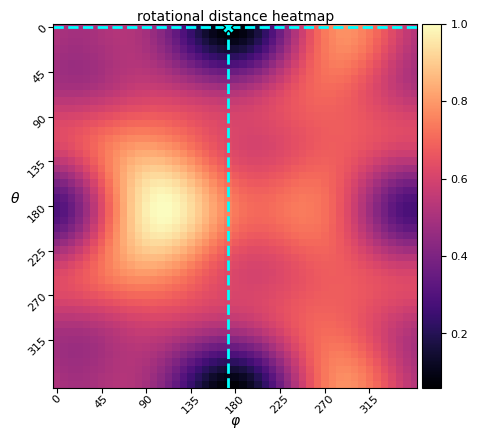

In [11]:
print('min_theta = ', min_theta)
print('  min_phi = ', min_phi)
print('\n')
plots.rotational_distance_heatmap(dists_sw_theta_phi)

In [12]:
### Next try fast rotations with 2D DFT
### axes are flipped compared to previous, is it the indexing of slice?
### should I add the conjugation? transpose at end?

n_phi, n_points, n_theta = U.shape
thetas = np.linspace(0, 2*np.pi, n_theta, endpoint=False)
phis = np.linspace(0, 2*np.pi, n_phi, endpoint=False)

C = np.zeros(U.shape)

t = time.time()

U_norm = np.linalg.norm(U)**2
V_norm = np.linalg.norm(V)**2

for s in range(n_points):
    
    U_slice = U[:, s, :]
    V_slice = V[:, s, :]
    
    C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.conj(np.fft.fft2(V_slice))).real
    # C = C * np.sin(thetas)[:, np.newaxis]
    # C[:, s, :] =  np.fft.ifft2(np.fft.fft2(U_slice) * np.fft.fft2(V_slice)).real

dists_sw_theta_phi = U_norm + V_norm - 2*np.sum(C, axis=1)

print('rotation distance time: ', time.time() - t)

rotation distance time:  0.010556459426879883


In [13]:
dists_sw_theta_phi = dists_sw_theta_phi / np.amax(dists_sw_theta_phi)

min_theta, min_phi = np.round(np.rad2deg(distances.return_min_angles(dists_sw_theta_phi, thetas, phis)), 2)

min_theta =  168.98
  min_phi =  0.0




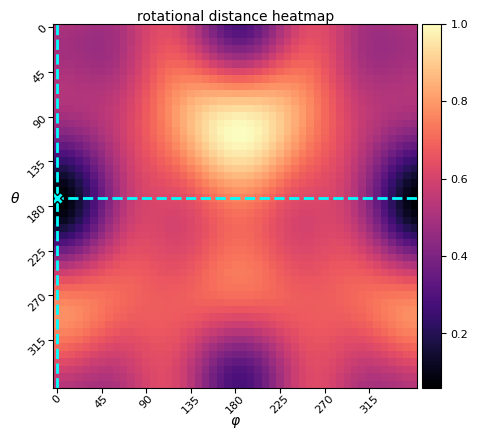

In [14]:
print('min_theta = ', min_theta)
print('  min_phi = ', min_phi)
print('\n')
plots.rotational_distance_heatmap(dists_sw_theta_phi)

In [15]:
np.rad2deg(thetas)

array([  0.        ,   7.34693878,  14.69387755,  22.04081633,
        29.3877551 ,  36.73469388,  44.08163265,  51.42857143,
        58.7755102 ,  66.12244898,  73.46938776,  80.81632653,
        88.16326531,  95.51020408, 102.85714286, 110.20408163,
       117.55102041, 124.89795918, 132.24489796, 139.59183673,
       146.93877551, 154.28571429, 161.63265306, 168.97959184,
       176.32653061, 183.67346939, 191.02040816, 198.36734694,
       205.71428571, 213.06122449, 220.40816327, 227.75510204,
       235.10204082, 242.44897959, 249.79591837, 257.14285714,
       264.48979592, 271.83673469, 279.18367347, 286.53061224,
       293.87755102, 301.2244898 , 308.57142857, 315.91836735,
       323.26530612, 330.6122449 , 337.95918367, 345.30612245,
       352.65306122])